# Sequential vs parallel quicksort: where is the threshold?

**Question:** from which array size does `parallelQuicksort` (pthreads, `THREAD_LEVEL=10`) beat the sequential quicksort on this machine?

**Machine:** Intel Core i7-1185G7 (4 cores / 8 hardware threads), Linux 7.0, gcc 13.3, governor `powersave`, laptop on normal desktop load.
**Binary:** `src/parallelQuicksort` compiled with the repository Makefile (`-O0 -g`).

**Protocol** (`scripts/run_threshold_benchmark.sh`):
- 26 sizes log-spaced from $10^2$ to $10^7$, 20 repetitions each, so 520 runs.
- The run order is **shuffled**, so drift over time (temperature, background jobs) is spread evenly across sizes.
- In each run, the program sorts the *same* random array with the sequential, parallel and libc `qsort` versions. This means sequential and parallel can be compared **run by run** (paired).

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "lines.linewidth": 2})
COLORS = {"Sequential": "#2a78d6", "Parallel": "#eb6834", "Built-in": "#1baf7a"}

path = sorted(glob.glob("data/*_2026-10-18/threshold_*.csv"))[-1]
df = pd.read_csv(path)
print(path, df.shape)
print(open(path.rsplit("/", 1)[0] + "/environment.txt").read())
df.head()

data/yassine-HP-EliteBook-840-G8-Notebook-PC_2026-10-18/threshold_1717.csv (1560, 4)
CPU(s):                                  8
Model name:                              11th Gen Intel(R) Core(TM) i7-1185G7 @ 3.00GHz
Thread(s) per core:                      2
Core(s) per socket:                      4
CPU(s) scaling MHz:                      55%
7.0.0-38-generic
gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
powersave
 17:17:46 up  2:24,  1 user,  load average: 1.22, 1.33, 0.95



,run,size,type,time
0,1,25119,Sequential,0.004348
1,1,25119,Parallel,0.047385
2,1,25119,Built-in,0.003997
3,2,251,Sequential,0.000028
4,2,251,Parallel,0.009844


## 1. Sanity checks
Every (size, type) pair should have 20 measurements, and the run order should really be mixed.

In [2]:
print(df.groupby(["size", "type"]).size().unstack().describe().loc[["min", "max"]])
order = df[df.type == "Sequential"][["run", "size"]]
print("Spearman corr(run index, size) =", round(stats.spearmanr(order["run"], order["size"])[0], 3))

type  Built-in  Parallel  Sequential
min       20.0      20.0        20.0
max       20.0      20.0        20.0
Spearman corr(run index, size) = 0.039


## 2. Raw execution times
Both axes are log scale. Dots are individual runs, lines are medians.

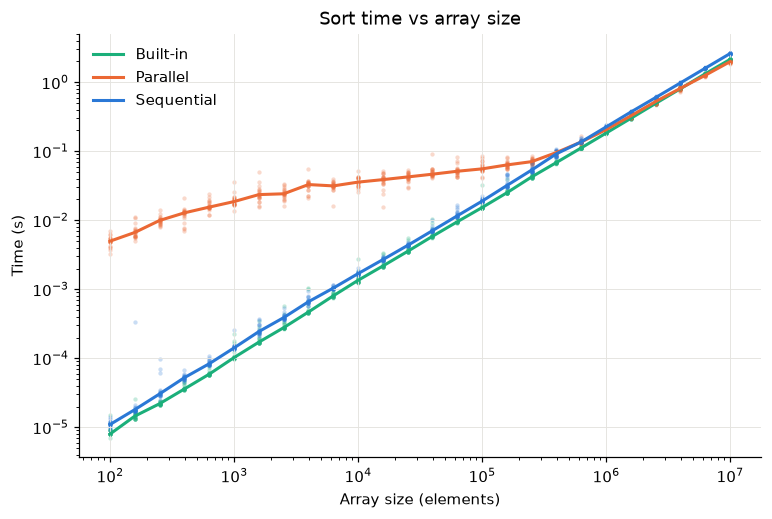

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
for t, g in df.groupby("type"):
    ax.scatter(g["size"], g.time, s=8, alpha=0.25, color=COLORS[t], linewidths=0)
    med = g.groupby("size").time.median()
    ax.plot(med.index, med.values, color=COLORS[t], label=t)
ax.set(xscale="log", yscale="log", xlabel="Array size (elements)", ylabel="Time (s)",
       title="Sort time vs array size")
ax.legend(frameon=False)
plt.show()

For small arrays, the parallel version has a near-constant cost of about **5–50 ms**. This is thread overhead: with `THREAD_LEVEL=10` the recursion creates up to $2^{11}-1 = 2047$ threads, whatever the array size. Sequential time grows roughly as $n \log n$, and the two curves only meet around $10^5$–$10^6$ elements.

## 3. Speed-up = Sequential / Parallel (paired per run)
For each run we compute `seq_time / par_time` on the same input. The band is a bootstrap 95% confidence interval of the median speed-up.

In [4]:
w = df.pivot_table(index=["run", "size"], columns="type", values="time").reset_index()
w["speedup"] = w.Sequential / w.Parallel

rng = np.random.default_rng(0)
def boot_ci(x, n=5000):
    meds = np.median(rng.choice(x, (n, len(x))), axis=1)
    return np.percentile(meds, [2.5, 97.5])

rows = []
for s, g in w.groupby("size"):
    lo, hi = boot_ci(g.speedup.values)
    p = stats.wilcoxon(g.Sequential, g.Parallel, alternative="greater").pvalue
    rows.append(dict(size=s, median_speedup=g.speedup.median(), ci_low=lo, ci_high=hi,
                     frac_par_faster=(g.speedup > 1).mean(), wilcoxon_p=p))
sp = pd.DataFrame(rows)
sp.style.format({"median_speedup": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}",
                 "frac_par_faster": "{:.0%}", "wilcoxon_p": "{:.1e}"})

,size,median_speedup,ci_low,ci_high,frac_par_faster,wilcoxon_p
0,100,0.002,0.002,0.002,0%,1.0e+00
1,158,0.003,0.002,0.003,0%,1.0e+00
2,251,0.003,0.003,0.003,0%,1.0e+00
3,398,0.004,0.004,0.005,0%,1.0e+00
4,631,0.005,0.005,0.006,0%,1.0e+00
5,1000,0.008,0.007,0.008,0%,1.0e+00
6,1585,0.011,0.010,0.012,0%,1.0e+00
7,2512,0.016,0.015,0.018,0%,1.0e+00
8,3981,0.021,0.019,0.023,0%,1.0e+00
9,6310,0.033,0.031,0.034,0%,1.0e+00


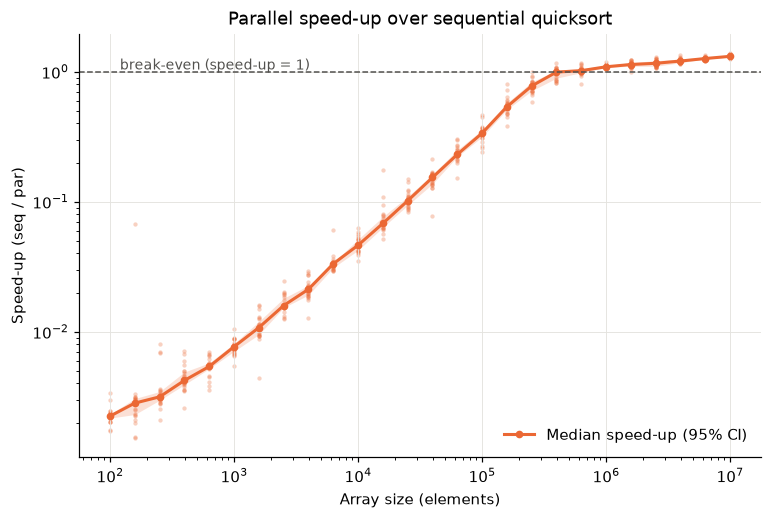

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(sp["size"], sp.ci_low, sp.ci_high, color=COLORS["Parallel"], alpha=0.2, linewidth=0)
ax.scatter(w["size"], w.speedup, s=8, alpha=0.3, color=COLORS["Parallel"], linewidths=0)
ax.plot(sp["size"], sp.median_speedup, color=COLORS["Parallel"], marker="o", markersize=4, label="Median speed-up (95% CI)")
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.text(1.2e2, 1.04, "break-even (speed-up = 1)", color="#52514e", fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="Array size (elements)", ylabel="Speed-up (seq / par)",
       title="Parallel speed-up over sequential quicksort")
ax.legend(frameon=False, loc="lower right")
plt.show()

## 4. Estimating the threshold

In [ ]:

x, y = np.log10(sp["size"].values), np.log(sp.median_speedup.values)
i = np.where((y[:-1] < 0) & (y[1:] >= 0))[0][0]
cross = 10 ** (x[i] - y[i] * (x[i+1] - x[i]) / (y[i+1] - y[i]))

above = sp.ci_low > 1
safe = sp["size"][above & above[::-1].cummin()[::-1]].min()

print(f"Median break-even (interpolated): ~{cross:,.0f} elements")
print(f"Parallel significantly faster (CI > 1 for all larger sizes): from {safe:,} elements")
print(f"Max median speed-up observed: {sp.median_speedup.max():.2f}x at n = {sp.loc[sp.median_speedup.idxmax(), 'size']:,}")

Median break-even (interpolated): ~443,077 elements
Parallel significantly faster (CI > 1 for all larger sizes): from 1,000,000 elements
Max median speed-up observed: 1.31x at n = 10,000,000


## 5. Conclusion

- **Up to ~250k elements, sequential always wins** (in 100% of the runs). For small arrays it wins by orders of magnitude (~130× at $n=10^3$), because creating ~2000 threads dominates the run time.
- **Break-even is at roughly 0.4 - 0.6 M elements** (about 3 to 5 MB of doubles); the interpolated median crossing is at about 440k. At $n \approx 4\times10^5$ and $6.3\times10^5$ each version wins about half of the runs, and the difference is not significant.
- **From $10^6$ elements on, parallel is reliably faster**: it wins ≥95% of the runs (p < 1e-5), and the confidence interval stays above 1 for every larger size.
- **The gain is modest:** about 1.3× at $10^7$ on 4 cores / 8 threads. Likely causes, in this code rather than in the machine:
  - the first `partition` call(s) run alone on a single thread (Amdahl);
  - `partition` calls `rand()`, which is protected by a global lock in glibc, so threads contend on it (the run spent ~7.5 min in *sys* time out of ~9 min of *user* time);
  - `THREAD_LEVEL=10` launches 2047 threads for 8 hardware threads;
  - the code is compiled with `-O0`.

**Limits of this experiment:** one machine, `powersave` governor (frequency scaling and turbo are uncontrolled), a laptop under normal desktop load, and a single input distribution (uniform random doubles). The threshold depends on `THREAD_LEVEL` and on the compiler flags, so it should be measured again if either one changes.